# Roteiro 10 - Redes Neurais II - Treinamento

Este é o roteiro da décima primeira aula de laboratório da disciplina de Inteligência Artificial ministrada em 2024-2025 na UFMT.

O objetivo é treinar um classificador utilizando uma rede neural de três camadas para a base de dados de dígitos manuscritos MNIST (Modified National Institute of Standards and Technology).



O documento está organizado da seguinte forma:


1.   Implementação da função de custo e regularização  
2.   Implementação algoritmo backpropagation (**Exercício 2.5 ponto**)
2.   Implementação do método de verificação de gradiente usando diferenças finitas.
3.   Implementação de redes neurais usando o framework PyTorch

---
Autor: raoni.teixeira@ufmt.br

# 1.  Carregando pacotes

In [ ]:
import numpy as np
from scipy.io import loadmat
from scipy.optimize import minimize
import matplotlib.pyplot as plt

# 2. Baixando dados
Baixar o dataset (imagens X e classe y)

In [ ]:
!gdown 1zyLpE4VpOd32vVkVBzH_Xy1V4u7rXMJz


Downloading...
From (original): https://drive.google.com/uc?id=1zyLpE4VpOd32vVkVBzH_Xy1V4u7rXMJz
From (redirected): https://drive.google.com/uc?id=1zyLpE4VpOd32vVkVBzH_Xy1V4u7rXMJz&confirm=t&uuid=532f50ff-a71e-4f00-897f-e325399d99e9
To: /content/mnistdata.mat
100% 7.51M/7.51M [00:00<00:00, 16.0MB/s]


Novamente, o conjunto de dados utilizado é uma pequena parte da base
[MNIST](https://pt.wikipedia.org/wiki/Banco_de_dados_MNIST) de dı́gitos manuscritos (arquivo `mnistdata.mat.`).

A amostra considerada contém $5.000$ imagens de tamanho $20 \times 20$, normalizadas no intervalo $[0-1]$.


Cada imagem dessa base de dados é uma matriz $20 \times 20 \in \mathbf{R}²$ .  A matriz armazena a intensidade do pixel em tons de cinza. Os valores $0$ e $1$ correspondem as cores preta e branca, respectivamente. Quanto mais perto de $0$ mais escuro é o pixel. Veja a Figura abaixo.

In [ ]:
def load_data():
    data = loadmat("mnistdata.mat")
    X = data["X"]
    y = data["y"].flatten()
    return X, y

print("Carregando dados...")
X, y = load_data()

Carregando dados...


# 3. Visualizando uma amostra de imagens

In [ ]:
def display_random_images(X, y):
    indices = np.random.choice(X.shape[0], 100, replace=False)
    images = X[indices, :].reshape(-1, 20, 20).transpose(0, 2, 1)
    labels = y[indices]

    fig, axes = plt.subplots(10, 10, figsize=(8, 8))
    for i, ax in enumerate(axes.flat):
        ax.imshow(images[i], cmap='gray')
        ax.set_title(f"{labels[i]}", fontsize=8)
        ax.axis('off')
    plt.tight_layout()
    plt.show()
display_random_images(X, y)


# 4. Modelo


A Figura abaixo mostra a arquitetura da rede neural considerada nesta atividade.

A rede possui três camadas: entrada, intermedária e saı́da.

Como estamos trabalhando com imagens de tamanho $20 \times 20$, a camada de entrada tem $400$ unidades (uma unidade para cada pixel da imagem).
A camada intermediária possui $25$ unidades e a camada de saída, $10$ unidades (uma para cada dı́gito possı́vel).
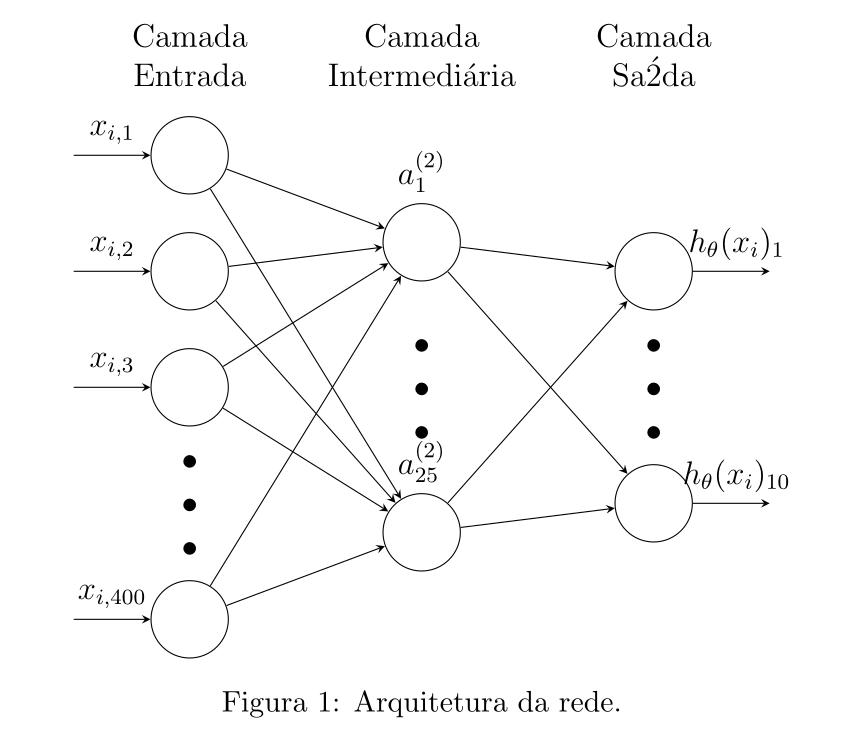

# 5. Função de Custo e Gradiente - Exercício (2.5 pontos)

A função `cost_function` implementa o cálculo do custo (erro) de uma rede neural e seus gradientes usando o método de backpropagation.

A função recebe todos os parâmetros da rede neural em um único vetor `nn_params` e os reorganiza nas matrizes e vetores corretos:

- `W2`: Matriz de pesos entre a camada de entrada e a camada escondida
- `b2`: Vetor de bias da camada escondida
- `W3`: Matriz de pesos entre a camada escondida e a camada de saída
- `b3`: Vetor de bias da camada de saída

# Execício (2.5 pontos) - Implemente o cálculo dos gradientes na função de custo a seguir

Preencha adequadamente as matrizes

- `W3_grad`  
- `b3_grad`  
- `W2_grad`  
- `b2_grad`  
    

Lembre-se de que o cálculo do erro e dos gradientes segue três passos principais:

 1. Calcular o erro na camada de saída:
    \begin{equation}
        \delta^{[L]} = a^{[L]} - y.
    \end{equation}
    
2. Para cada camada $(\ell \in \{L-1, L-2, \ldots, 2\}$, propagar o erro para trás:
    \begin{equation}
        \delta^{[\ell]} = (W^{[\ell+1]} \circ \delta^{[\ell+1]}) \sigma'(z^{[\ell]}),        
    \end{equation}
em que $\circ$ representa a multiplicação elemento a elemento, e $\sigma'$ é a derivada da função de ativação (implementada em `sigmoid_gradient`).

3. Calcular os gradientes para atualização dos parâmetros:
    \begin{equation}
        \frac{\partial J}{\partial W^{[\ell]}} = \delta^{[\ell]} a^{[\ell-1]T},
        \quad
        \frac{\partial J}{\partial b^{[\ell]}} = \delta^{[\ell]}.
    \end{equation}


In [ ]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def sigmoid_gradient(z):
    return sigmoid(z) * (1 - sigmoid(z))


def cost_function(nn_params, input_layer_size, hidden_layer_size, num_labels, X, y, lambda_):
    # Extrair os parâmetros
    W2_size = hidden_layer_size * input_layer_size
    b2_size = hidden_layer_size
    W3_size = num_labels * hidden_layer_size
    b3_size = num_labels

    W2 = nn_params[:W2_size].reshape(hidden_layer_size, input_layer_size)
    b2 = nn_params[W2_size:W2_size + b2_size].reshape(1, hidden_layer_size)
    W3 = nn_params[W2_size + b2_size:W2_size + b2_size + W3_size].reshape(num_labels, hidden_layer_size)
    b3 = nn_params[W2_size + b2_size + W3_size:].reshape(1, num_labels)

    m = X.shape[0]
    a1 = X
    Y = np.eye(num_labels)[y.flatten() - 1]

    # Forward propagation
    z2 = a1 @ W2.T + b2
    a2 = sigmoid(z2)

    z3 = a2 @ W3.T + b3
    a3 = sigmoid(z3)

    # Cálculo do custo
    J = -np.sum(Y * np.log(a3) + (1 - Y) * np.log(1 - a3)) / m
    reg = (lambda_ / (2 * m)) * (np.sum(W2 ** 2) + np.sum(W3 ** 2))
    J += reg

    # Backpropagation
    delta3 = a3 - Y
    delta2 = (delta3 @ W3) * sigmoid_gradient(z2)

    # Gradientes
    #COLOQUE SEU CODIGO AQUI



    # Regularização (aplicada apenas aos pesos, não aos biases)
    W3_grad += (lambda_ / m) * W3
    W2_grad += (lambda_ / m) * W2

    # Juntar todos os gradientes
    grad = np.concatenate([W2_grad.ravel(), b2_grad.ravel(), W3_grad.ravel(), b3_grad.ravel()])

    return J, grad

# 6. Verificando sua implementação

A função `checkNNGradients`  valida a implementação do algoritmo de backpropagation anterior. Esta função implementa uma técnica conhecida como "verificação de gradiente" (gradient checking), que compara os gradientes obtidos pelo método analítico (backpropagation) com o valores obtidos numericamente.

A função `computeNumericalGradient` calcula os gradientes usando o método de diferenças finitas:
\begin{equation}
 f'(x)={\frac {f(x+\epsilon)-f(x-\epsilon)}{2\epsilon}}
 \end{equation}
Para cada parâmetro, o custo é calculado após uma pequena perturbação positiva ($\epsilon$) e negativa ($-\epsilon$) e o gradiente é aproximado como a diferença entre a soma desses custos dividida por duas vezes o tamanho da perturbação.

Esta abordagem, embora computacionalmente ineficiente para ser aplicada no treinamento, é uma estimativa precisa para ser usada como referência na verificação da implementação.


In [ ]:
def computeNumericalGradient(costFunc, theta):
    numgrad = np.zeros(theta.shape)
    perturb = np.zeros(theta.shape)
    epsilon = 1e-4

    for i in range(len(theta)):
        perturb[i] = epsilon
        loss1 = costFunc(theta - perturb)[0]
        loss2 = costFunc(theta + perturb)[0]
        numgrad[i] = (loss2 - loss1) / (2 * epsilon)
        perturb[i] = 0

    return numgrad

def debugInitializeWeights(fan_out, fan_in):
    return np.sin(np.arange(1, (fan_out * fan_in) + 1)).reshape(fan_out, fan_in) / 10.0

def debugInitializeBias(size):
    return np.sin(np.arange(1, size + 1)).reshape(1, size) / 10.0

def checkNNGradients(lambda_):
    input_layer_size = 3
    hidden_layer_size = 5
    num_labels = 3
    m = 5

    W2 = debugInitializeWeights(hidden_layer_size, input_layer_size)
    b2 = debugInitializeBias(hidden_layer_size)
    W3 = debugInitializeWeights(num_labels, hidden_layer_size)
    b3 = debugInitializeBias(num_labels)

    X = debugInitializeWeights(m, input_layer_size)
    y = np.array([i % num_labels + 1 for i in range(1, m + 1)])

    nn_params = np.concatenate([W2.ravel(), b2.ravel(), W3.ravel(), b3.ravel()])
    costFunc = lambda p: cost_function(p, input_layer_size, hidden_layer_size, num_labels, X, y, lambda_)

    grad = computeNumericalGradient(costFunc, nn_params)
    _, grad_analytic = costFunc(nn_params)

    print("Numerical Gradient vs Analytical Gradient:")
    print(np.c_[grad, grad_analytic])

    diff = np.linalg.norm(grad - grad_analytic) / np.linalg.norm(grad + grad_analytic)
    print(f"Relative Difference: {diff}")

lambda_ = 1.0
checkNNGradients(lambda_ )



Numerical Gradient vs Analytical Gradient:
[[ 0.01636005  0.01636005]
 [ 0.01767279  0.01767279]
 [ 0.00273725  0.00273725]
 [-0.01544934 -0.01544934]
 [-0.01932945 -0.01932945]
 [-0.00543815 -0.00543815]
 [ 0.01327021  0.01327021]
 [ 0.02013692  0.02013692]
 [ 0.00848984  0.00848984]
 [-0.01042573 -0.01042573]
 [-0.0194706  -0.0194706 ]
 [-0.01061429 -0.01061429]
 [ 0.00876368  0.00876368]
 [ 0.02003382  0.02003382]
 [ 0.01288496  0.01288496]
 [ 0.00315913  0.00315913]
 [ 0.0081925   0.0081925 ]
 [ 0.00571113  0.00571113]
 [-0.00203903 -0.00203903]
 [-0.00789535 -0.00789535]
 [ 0.18584197  0.18584197]
 [ 0.18852471  0.18852471]
 [ 0.16612854  0.16612854]
 [ 0.14167148  0.14167148]
 [ 0.13520811  0.13520811]
 [ 0.06691064  0.06691064]
 [ 0.08516714  0.08516714]
 [ 0.08996542  0.08996542]
 [ 0.07441755  0.07441755]
 [ 0.05555814  0.05555814]
 [ 0.03695375  0.03695375]
 [ 0.04551184  0.04551184]
 [ 0.06339483  0.06339483]
 [ 0.07162432  0.07162432]
 [ 0.06491943  0.06491943]
 [ 0.3251184

A saída mostra a comparação dos dois conjuntos de gradientes.

Os gradientes são exibidos lado a lado para inspeção visual e, por fim,
uma medida de diferença relativa é calculada usando a norma euclidiana.

O valor da diferença relativa deve ser muito pequeno (tipicamente menor que $1e-9$) para uma implementação correta. Valores maiores indicam possíveis erros na implementação do backpropagation.

# 7. Treinando a rede

Agora que já temos o backpropagation funcionando podemos treinar a nossa rede neural.

A otimização é realizada usando a função `minimize` do pacote `scipy.optimize`.


In [ ]:
#Aquitetura da Rede Neural
input_layer_size = 400
hidden_layer_size = 25
num_labels = 10
lambda_ = 1

# Inicialização dos pesos de forma separada
initial_W2 = np.random.rand(hidden_layer_size, input_layer_size) * 0.12 - 0.06
initial_b2 = np.zeros((1, hidden_layer_size))
initial_W3 = np.random.rand(num_labels, hidden_layer_size) * 0.12 - 0.06
initial_b3 = np.zeros((1, num_labels))

initial_nn_params = np.concatenate([
    initial_W2.ravel(),
    initial_b2.ravel(),
    initial_W3.ravel(),
    initial_b3.ravel()
])

print("Treinando a rede neural...")
options = {'maxiter': 50}

costFunc = lambda p: cost_function(p, input_layer_size, hidden_layer_size, num_labels, X, y, lambda_)

result = minimize(fun=lambda p: costFunc(p)[0], x0=initial_nn_params,
                  jac=lambda p: costFunc(p)[1], method='CG', options=options)

nn_params = result.x

# Extrair os parâmetros após o treinamento
W2_size = hidden_layer_size * input_layer_size
b2_size = hidden_layer_size
W3_size = num_labels * hidden_layer_size

W2 = nn_params[:W2_size].reshape(hidden_layer_size, input_layer_size)
b2 = nn_params[W2_size:W2_size + b2_size].reshape(1, hidden_layer_size)
W3 = nn_params[W2_size + b2_size:W2_size + b2_size + W3_size].reshape(num_labels, hidden_layer_size)
b3 = nn_params[W2_size + b2_size + W3_size:].reshape(1, num_labels)

print("Rede treinada com sucesso!")

# Testando a rede
pred = predict(W2, b2, W3, b3, X)
accuracy = np.mean(pred == y) * 100
print(f"Precisão do treinamento: {accuracy:.2f}%")


Treinando a rede neural...
Rede treinada com sucesso!
Precisão do treinamento: 95.98%


# 8. Implementação com PyTorch

Nesta seção, o mesmo modelo implementado com o framework PyTorch,  

PyTorch é um dos frameworks de aprendizado profundo mais utilizados na comunidade de pesquisa e desenvolvimento. De acordo com a pesquisa anual de ferramentas de ML realizada pela Kaggle em 2023, PyTorch é utilizado por aproximadamente 64% dos profissionais e pesquisadores de aprendizado de máquina, superando o TensorFlow em vários segmentos, especialmente em ambientes acadêmicos e de pesquisa. Um estudo da Gradient Flow mostrou que PyTorch é o framework preferido em 77% dos artigos publicados nas principais conferências de IA, como NeurIPS, ICML e ICLR.

Consulte os [tutorias](https://pytorch.org/tutorials/) e o [manual](https://pytorch.org/tutorials/beginner/basics/intro.html) do PyTorch para mais detalhes


Carregue os pacotes

In [ ]:
import numpy as np
from scipy.io import loadmat
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

## Modelo

A classe `NeuralNet` implementa a rede de três camadas. Os parâmetros `fc1` e `fc2`  são automaticamente rastreados para cálculo de gradientes (backpropagation).

 - `fc1` é a matriz que conecta a camada de entrada à escondida, e
 - `fc2` conecta a camada escondida à camada de saída.

 O método `forward` define o fluxo de dados através do modelo, aplicando a função de ativação sigmoid após cada camada linear.

In [ ]:
class NeuralNet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super(NeuralNet, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.sigmoid = nn.Sigmoid()
        self.fc2 = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        x = self.sigmoid(self.fc1(x))
        x = self.sigmoid(self.fc2(x))
        return x

O código abaixo faz o treinamento do modelo.

O treinamento possui quatro passos principais:
- zeragem dos gradientes anteriores com `optimizer.zero_grad()`,
- cálculo da saída do modelo,
- computação da função de perda e
- propagação reversa dos gradientes com `loss.backward(`), seguido da atualização dos parâmetros via `optimizer.step()`.

O framework calcula as derivadas automaticamente.

A declaração with `torch.no_grad()` na fase de avaliação desativa temporariamente o mecanismo de rastreamento de gradientes, economizando memória e aumentando a velocidade de execução durante a inferência.
Durante a avaliação, estamos interessados apenas na saída do modelo, não sendo necessário calcular gradientes para atualização de parâmetros.

In [ ]:
print("Carregando os dados...")
data = loadmat("mnistdata.mat")
X = data['X']
y = data['y'].flatten()
y[y == 10] = 0  # Converte classe 10 para 0 (PyTorch exige rótulos de 0 a 9)

X_tensor = torch.FloatTensor(X)
y_tensor = torch.LongTensor(y)

dataset = TensorDataset(X_tensor, y_tensor)
dataloader = DataLoader(dataset, batch_size=64, shuffle=True)

input_layer_size = 400
hidden_layer_size = 25
num_labels = 10
lambda_ = 0.0

model = NeuralNet(input_layer_size, hidden_layer_size, num_labels)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.01, weight_decay=lambda_)

print("Treinando a rede neural com PyTorch...")
num_epochs = 20
for epoch in range(num_epochs):
    running_loss = 0.0
    for i, (inputs, labels) in enumerate(dataloader):
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    print(f"Época {epoch + 1}/{num_epochs}, Loss: {running_loss / len(dataloader):.4f}")

print("Treinamento concluído!")

with torch.no_grad():
    outputs = model(X_tensor)
    _, predicted = torch.max(outputs, 1)
    accuracy = (predicted == y_tensor).float().mean().item()
    print(f"Acurácia no conjunto de treinamento: {accuracy * 100:.2f}%")


Carregando os dados...
Treinando a rede neural com PyTorch...
Época 1/20, Loss: 1.9803
Época 2/20, Loss: 1.7000
Época 3/20, Loss: 1.6274
Época 4/20, Loss: 1.5942
Época 5/20, Loss: 1.5720
Época 6/20, Loss: 1.5561
Época 7/20, Loss: 1.5462
Época 8/20, Loss: 1.5379
Época 9/20, Loss: 1.5309
Época 10/20, Loss: 1.5234
Época 11/20, Loss: 1.5189
Época 12/20, Loss: 1.5158
Época 13/20, Loss: 1.5117
Época 14/20, Loss: 1.5105
Época 15/20, Loss: 1.5074
Época 16/20, Loss: 1.5045
Época 17/20, Loss: 1.5028
Época 18/20, Loss: 1.5010
Época 19/20, Loss: 1.4991
Época 20/20, Loss: 1.4983
Treinamento concluído!
Acurácia no conjunto de treinamento: 97.06%
